# 02 · Choosing and fine-tuning the vehicle detector

**Project:** Traffic Density and Congestion Estimation from Single Images

This notebook (1) picks the detector architecture on the **validation** set and (2) fine-tunes it on
our 5 vehicle classes (`car`, `two_wheeler`, `auto_rickshaw`, `bus`, `truck`), saving the weights to
`weights/`.

* **Candidates:** the two newest Ultralytics generations at the *small* size, which fit the 4 GB
  laptop GPU: **YOLO11s** (2024) and **YOLO26s** (2026). YOLOv8s is two generations older and is not
  considered; YOLO12 was ruled out because its attention layers are slow and memory-hungry
  without FlashAttention on a 4 GB card.
* **Selection (stage 1):** both candidates get the *same* short fine-tune (same data subset, epochs,
  image size, batch and seed); the one with the higher validation mAP@0.5:0.95 wins (ties within 0.005
  go to the faster model).
* **Stage 2:** the winner continues training from its stage-1 checkpoint on all training images.
* **Optional to re-run.** The submission notebook `traffic_flow_main.ipynb` only *loads* the saved
  weights; it never retrains. The **test** split is never used here: the runtime data file below
  contains only train and val.
* `SMOKE_TEST = True` runs everything for 1-2 epochs on the tiny coco128-vehicle sample
  (`data_smoke/`) only to prove the code works; those weights get a `SMOKE_` name and are **not** results.

## 1. Setup

In [1]:
# ------------------------------------------------------------------------------------------
# Environment setup. The same cell works locally (VS Code, .venv kernel) and in Google Colab.
# ------------------------------------------------------------------------------------------
import os, sys, random, subprocess, time, json, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Mount Google Drive and locate the project folder (the one that contains trafficlib.py).
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_FOLDER_NAME = "TrafficProject"   # <- change if your Drive folder has another name
    my_drive = Path("/content/drive/MyDrive")
    candidates = [my_drive / DRIVE_FOLDER_NAME, *my_drive.glob(f"*/{DRIVE_FOLDER_NAME}"),
                  *my_drive.glob(f"*/*/{DRIVE_FOLDER_NAME}")]
    PROJECT_DIR = next((p for p in candidates if (p / "trafficlib.py").exists()), None)
    assert PROJECT_DIR is not None, (
        f"Could not find {DRIVE_FOLDER_NAME}/trafficlib.py in My Drive. If the folder was shared with "
        "you, right-click it > Organize > Add shortcut to My Drive, or edit DRIVE_FOLDER_NAME.")
    # Colab already ships torch, torchvision, transformers, OpenCV, pandas, matplotlib, scikit-learn.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.218", "imagehash"],
                   check=True)
else:
    # Local run: paths are relative to the notebook's own folder (no absolute paths).
    here = Path.cwd()
    PROJECT_DIR = here if (here / "trafficlib.py").exists() else here.parent
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))
print("project folder:", PROJECT_DIR.name, "| running in Colab:", IN_COLAB)

project folder: TrafficProject | running in Colab: False


In [2]:
# Core libraries + fixed seeds (42) so every run gives the same numbers.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

torch 2.14.1+cu126 | device: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Training configuration
All training constants are in this one cell. Image size 960 (instead of the default 640) keeps small,
distant two-wheelers detectable in 1080p CCTV frames. Batch 4 keeps both candidates inside the 4 GB
of the RTX 3050 (at batch 6 YOLO26s needed 4.4 GB and spilled into slow shared memory); Ultralytics
accumulates gradients to a nominal batch of 64, so the effective batch size is the same.

In [3]:
SMOKE_TEST = False               # True = quick code check on data_smoke/ (NOT a result)

CANDIDATES      = ["yolo11s.pt", "yolo26s.pt"]   # COCO-pretrained, downloaded into weights/
SELECT_EPOCHS   = 8                # short, identical fine-tune for each candidate
SELECT_FRACTION = 0.5              # ... on the first 50% of the training images
EPOCHS          = 10               # stage 2: continue the winner's checkpoint on ALL training images
PATIENCE        = 4                # early stopping: stop if val fitness stalls for 4 epochs
REUSE_SELECTION = True             # re-use finished selection runs (delete model_selection.csv to redo)
CACHE           = False            # no image cache: the laptop has too little free RAM (15 GB total)
IMGSZ           = 960              # training / inference size (long side, pixels)
BATCH           = 4                # images per step; gradients are accumulated to a nominal batch of 64
WORKERS         = 2                # data-loading processes; Ultralytics starts 2x for validation, each ~0.6 GB RAM
DATA_DIR        = PROJECT_DIR / "data"
PREFIX          = ""

if SMOKE_TEST:
    SELECT_EPOCHS, SELECT_FRACTION, EPOCHS, PATIENCE = 1, 1.0, 2, 2
    DATA_DIR, PREFIX = PROJECT_DIR / "data_smoke", "SMOKE_"

# Quiet Ultralytics' per-batch progress bars (they would flood the notebook); we print one line
# per epoch ourselves. Must be set before ultralytics is imported.
os.environ["YOLO_VERBOSE"] = "False"
OUT_TRAIN = PROJECT_DIR / "outputs" / "training"
OUT_TRAIN.mkdir(parents=True, exist_ok=True)
print(f"SMOKE_TEST={SMOKE_TEST} | data={DATA_DIR.name} | candidates={CANDIDATES} | imgsz={IMGSZ} | batch={BATCH}")

SMOKE_TEST=False | data=data | candidates=['yolo11s.pt', 'yolo26s.pt'] | imgsz=960 | batch=4


## 3. Data check
Images and boxes per split, and a runtime data file for Ultralytics that contains **only train and
val** (its absolute `path:` is computed at run time, so nothing is hard-coded).

In [4]:
import yaml
from trafficlib import CLASS_NAMES, list_images, read_yolo_labels, label_path_for

rows = []
for split in ["train", "val", "test"]:
    imgs = list_images(DATA_DIR / split / "images")
    cls = np.concatenate([read_yolo_labels(label_path_for(p))[:, 0] for p in imgs]) if imgs else np.zeros(0)
    rows.append({"split": split, "images": len(imgs), "boxes": len(cls),
                 **{c: int((cls == i).sum()) for i, c in enumerate(CLASS_NAMES)}})
display(pd.DataFrame(rows).set_index("split"))

runtime_yaml = PROJECT_DIR / "runs" / f"{PREFIX}train_val_data.yaml"
runtime_yaml.parent.mkdir(exist_ok=True)
runtime_yaml.write_text(yaml.safe_dump({"path": str(DATA_DIR.resolve()), "train": "train/images",
                                        "val": "val/images", "names": dict(enumerate(CLASS_NAMES))}))
print(runtime_yaml.read_text())

,images,boxes,car,two_wheeler,auto_rickshaw,bus,truck
split,,,,,,,
train,2241,29654,6883,13763,4622,1076,3310
val,480,5859,1432,2759,841,191,636
test,300,4027,923,1841,637,170,456


names:
  0: car
  1: two_wheeler
  2: auto_rickshaw
  3: bus
  4: truck
path: C:\Users\prade\Documents\Epoch_Zero\ComputerVision\TrafficProject\data
train: train/images
val: val/images



## 4. Training helpers
`train_run` fine-tunes one pretrained model and records wall-clock time and peak GPU memory;
`val_run` evaluates saved weights on the **validation** split.

In [5]:
from ultralytics import YOLO
from ultralytics.utils.downloads import attempt_download_asset
from ultralytics.utils.torch_utils import get_flops

GPU = 0 if DEVICE == "cuda" else "cpu"

def pretrained(name):
    """COCO-pretrained Ultralytics weights, stored in weights/ (downloaded once): from the official
    GitHub release, or, if that host is blocked on this network, from Ultralytics' own Hugging Face
    repositories (same files: Ultralytics/YOLO11, Ultralytics/YOLO26)."""
    path = PROJECT_DIR / "weights" / name
    if not path.exists():
        try:
            attempt_download_asset(str(path))
        except Exception as e:
            print(f"GitHub download failed ({type(e).__name__}); using the Ultralytics Hugging Face mirror")
            from huggingface_hub import hf_hub_download
            repo = "Ultralytics/YOLO11" if name.startswith("yolo11") else "Ultralytics/YOLO26"
            shutil.copy2(hf_hub_download(repo, name), path)
    return path

def make_epoch_logger(t_start):
    """One summary line per epoch. Ultralytics also calls on_fit_epoch_end for the final validation
    of best.pt; that call is recognised because training has already stopped."""
    state = {"stop_seen": False}
    def log(trainer):
        m = trainer.metrics or {}
        maps = (f"val mAP50 {m.get('metrics/mAP50(B)', float('nan')):.3f} "
                f"mAP50-95 {m.get('metrics/mAP50-95(B)', float('nan')):.3f}")
        if trainer.stop and state["stop_seen"]:
            print(f"   final check of best.pt   | {maps}", flush=True)
            return
        state["stop_seen"] |= bool(trainer.stop)
        tl = trainer.tloss if isinstance(trainer.tloss, dict) else {}
        box = next((float(v) for k, v in tl.items() if "box" in k), float("nan"))
        cls = next((float(v) for k, v in tl.items() if "cls" in k), float("nan"))
        print(f"   epoch {trainer.epoch + 1:3d}/{trainer.epochs} | train loss box {box:.3f} cls {cls:.3f} | "
              f"{maps} | {(time.time() - t_start) / 60:5.1f} min", flush=True)
    return log

def train_run(base, run_name, epochs, fraction=1.0, patience=PATIENCE):
    """base = a pretrained model name (yolo11s.pt) or a path to our own checkpoint."""
    model = YOLO(str(base if Path(base).exists() else pretrained(base)))
    t0 = time.time()
    model.add_callback("on_fit_epoch_end", make_epoch_logger(t0))
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    model.train(data=str(runtime_yaml), epochs=epochs, fraction=fraction, patience=patience, imgsz=IMGSZ,
                batch=BATCH, workers=WORKERS, cache=CACHE, device=GPU, seed=SEED, deterministic=True,
                project=str(PROJECT_DIR / "runs"), name=run_name, exist_ok=True, plots=True, verbose=False)
    minutes = (time.time() - t0) / 60
    vram = torch.cuda.max_memory_reserved() / 2**30 if DEVICE == "cuda" else float("nan")
    return Path(model.trainer.save_dir), minutes, vram

def val_run(weights):
    r = YOLO(str(weights)).val(data=str(runtime_yaml), split="val", imgsz=IMGSZ, batch=BATCH, device=GPU,
                               plots=False, verbose=False)
    return r

## 5. Model selection on the validation set
Identical short fine-tune for each candidate, then compare validation accuracy, model size, training
cost and inference speed **on this laptop**.

In [6]:
sel_rows = []
(PROJECT_DIR / "weights" / "model_selection").mkdir(parents=True, exist_ok=True)
sel_csv = OUT_TRAIN / f"{PREFIX}model_selection.csv"
sel_w = {Path(b).stem: PROJECT_DIR / "weights" / "model_selection" / f"{PREFIX}{Path(b).stem}_select_{SELECT_EPOCHS}ep.pt"
         for b in CANDIDATES}
reuse = REUSE_SELECTION and sel_csv.exists() and all(w.exists() for w in sel_w.values())
if reuse:
    print(f"re-using the finished selection runs: {sel_csv.relative_to(PROJECT_DIR).as_posix()} and "
          f"weights/model_selection/ (set REUSE_SELECTION = False to train the candidates again)")
for base in ([] if reuse else CANDIDATES):
    stem = Path(base).stem
    print(f"\n=== {stem}: {SELECT_EPOCHS} epochs on {SELECT_FRACTION:.0%} of the training images ===")
    run_dir, minutes, vram = train_run(base, f"{PREFIX}select_{stem}", SELECT_EPOCHS, SELECT_FRACTION,
                                       patience=SELECT_EPOCHS)
    w = PROJECT_DIR / "weights" / "model_selection" / f"{PREFIX}{stem}_select_{SELECT_EPOCHS}ep.pt"
    shutil.copy2(run_dir / "weights" / "best.pt", w)        # keep every trained model's weights
    v = val_run(w)
    net = YOLO(str(pretrained(base))).model
    sel_rows.append({"model": stem,
                     "params (M)": round(sum(p.numel() for p in net.parameters()) / 1e6, 2),
                     "GFLOPs @640": round(get_flops(net, 640), 1),
                     "val mAP50": round(float(v.box.map50), 4), "val mAP50-95": round(float(v.box.map), 4),
                     "train min/epoch": round(minutes / SELECT_EPOCHS, 2), "peak VRAM (GB)": round(vram, 2),
                     "inference ms/img": round(v.speed["inference"], 1)})
sel = pd.read_csv(sel_csv).set_index("model") if reuse else pd.DataFrame(sel_rows).set_index("model")
sel.to_csv(sel_csv)
display(sel)

# Winner: best val mAP50-95; within 0.005 of the best, prefer the faster model.
best_map = sel["val mAP50-95"].max()
close = sel[sel["val mAP50-95"] >= best_map - 0.005]
WINNER = close["inference ms/img"].idxmin() if len(close) > 1 else sel["val mAP50-95"].idxmax()
print(f"selected base model: {WINNER}" + ("   [SMOKE TEST - NOT A RESULT]" if SMOKE_TEST else ""))

re-using the finished selection runs: outputs/training/model_selection.csv and weights/model_selection/ (set REUSE_SELECTION = False to train the candidates again)


,params (M),GFLOPs @640,val mAP50,val mAP50-95,train min/epoch,peak VRAM (GB),inference ms/img
model,,,,,,,
yolo11s,9.46,21.8,0.8244,0.6678,1.33,2.42,13.1
yolo26s,10.01,23.1,0.8476,0.6949,1.32,3.17,13.4


selected base model: yolo26s


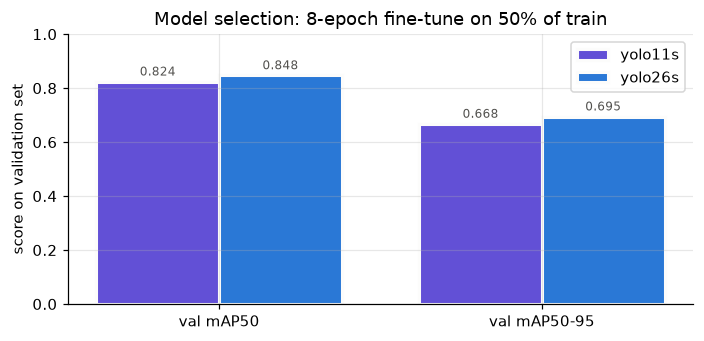

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
metrics = ["val mAP50", "val mAP50-95"]
x = np.arange(len(metrics))
colors = {"yolo11s": "#6250d6", "yolo26s": "#2a78d6"}
width = 0.38
for k, m in enumerate(sel.index):
    vals = sel.loc[m, metrics].values.astype(float)
    bars = ax.bar(x + (k - 0.5) * width, vals, width, color=colors.get(m, "#898781"), label=m,
                  edgecolor="#fcfcfb", linewidth=2)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, color="#52514e", padding=2)
ax.set_xticks(x, metrics)
ax.set_ylabel("score on validation set")
ax.set_ylim(0, 1)
ax.set_title(f"Model selection: {SELECT_EPOCHS}-epoch fine-tune on {SELECT_FRACTION:.0%} of train"
             + (" [SMOKE]" if SMOKE_TEST else ""))
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(OUT_TRAIN / f"{PREFIX}model_selection.png", bbox_inches="tight")
plt.show()

## 6. Stage 2: fine-tune the selected model on all training images
Stage 1 (the selection run above) already turned the COCO-pretrained model into a 5-class detector:
Ultralytics keeps the pretrained backbone and neck, replaces the 80-class head with a 5-class head and
fine-tunes the whole network. Stage 2 continues from the winner's stage-1 checkpoint on **all**
training images for up to `EPOCHS` epochs with early stopping on the validation set (optimizer by
Ultralytics' `auto` rule, default augmentation incl. mosaic, switched off for the last epochs).
Two short stages instead of one long run keep the 4 GB laptop GPU (and its temperature) under load
for about half an hour instead of several hours. `seed=42, deterministic=True` makes runs repeatable
on the same hardware.

In [8]:
RUN_NAME = f"{PREFIX}{WINNER}_traffic"
print(f"=== {WINNER}: stage 2, continue from its selection checkpoint on ALL training images, "
      f"up to {EPOCHS} epochs (early stopping patience {PATIENCE}) ===")
run_dir, train_minutes, peak_vram = train_run(sel_w[WINNER], RUN_NAME, EPOCHS)
print(f"training took {train_minutes:.1f} min, peak GPU memory {peak_vram:.2f} GB; run folder: runs/{run_dir.name}")

=== yolo26s: stage 2, continue from its selection checkpoint on ALL training images, up to 10 epochs (early stopping patience 4) ===


   epoch   1/10 | train loss box 0.877 cls 0.818 | val mAP50 0.806 mAP50-95 0.636 |   3.1 min


   epoch   2/10 | train loss box 0.933 cls 0.886 | val mAP50 0.798 mAP50-95 0.628 |   5.4 min


   epoch   3/10 | train loss box 0.944 cls 0.896 | val mAP50 0.823 mAP50-95 0.647 |   7.7 min


   epoch   4/10 | train loss box 0.929 cls 0.840 | val mAP50 0.832 mAP50-95 0.664 |  10.0 min


   epoch   5/10 | train loss box 0.901 cls 0.790 | val mAP50 0.852 mAP50-95 0.690 |  12.3 min


... (3 outputs left out)

   epoch   9/10 | train loss box 0.778 cls 0.634 | val mAP50 0.866 mAP50-95 0.724 |  21.1 min


   epoch  10/10 | train loss box 0.758 cls 0.619 | val mAP50 0.872 mAP50-95 0.730 |  23.2 min


   final check of best.pt   | val mAP50 0.872 mAP50-95 0.729


training took 23.4 min, peak GPU memory 3.10 GB; run folder: runs/yolo26s_traffic


## 7. Save the weights to `weights/`

In [9]:
OUT_WEIGHTS = PROJECT_DIR / "weights" / f"{PREFIX}{WINNER}_traffic_best.pt"
shutil.copy2(run_dir / "weights" / "best.pt", OUT_WEIGHTS)
shutil.copy2(run_dir / "results.csv", OUT_TRAIN / f"{RUN_NAME}_results.csv")
meta = {"base_model": f"{WINNER}.pt", "weights": OUT_WEIGHTS.relative_to(PROJECT_DIR).as_posix(),
        "init": f"stage 1 = selection run ({SELECT_EPOCHS} epochs on {SELECT_FRACTION:.0%} of train, from COCO weights); "
                f"stage 2 = this run on all training images",
        "smoke_test": SMOKE_TEST, "epochs_max": EPOCHS, "imgsz": IMGSZ, "batch": BATCH,
        "train_minutes": round(train_minutes, 1), "peak_vram_gb": round(peak_vram, 2), "device": DEVICE,
        "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
        "train_images": int(rows[0]["images"]), "val_images": int(rows[1]["images"])}
json.dump(meta, open(OUT_TRAIN / f"{PREFIX}selected_model.json", "w"), indent=2)
print(f"saved {meta['weights']} ({OUT_WEIGHTS.stat().st_size / 1e6:.1f} MB)")
print(json.dumps(meta, indent=2))

saved weights/yolo26s_traffic_best.pt (20.3 MB)
{
  "base_model": "yolo26s.pt",
  "weights": "weights/yolo26s_traffic_best.pt",
  "init": "stage 1 = selection run (8 epochs on 50% of train, from COCO weights); stage 2 = this run on all training images",
  "smoke_test": false,
  "epochs_max": 10,
  "imgsz": 960,
  "batch": 4,
  "train_minutes": 23.4,
  "peak_vram_gb": 3.1,
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU",
  "train_images": 2241,
  "val_images": 480
}


## 8. Training curves

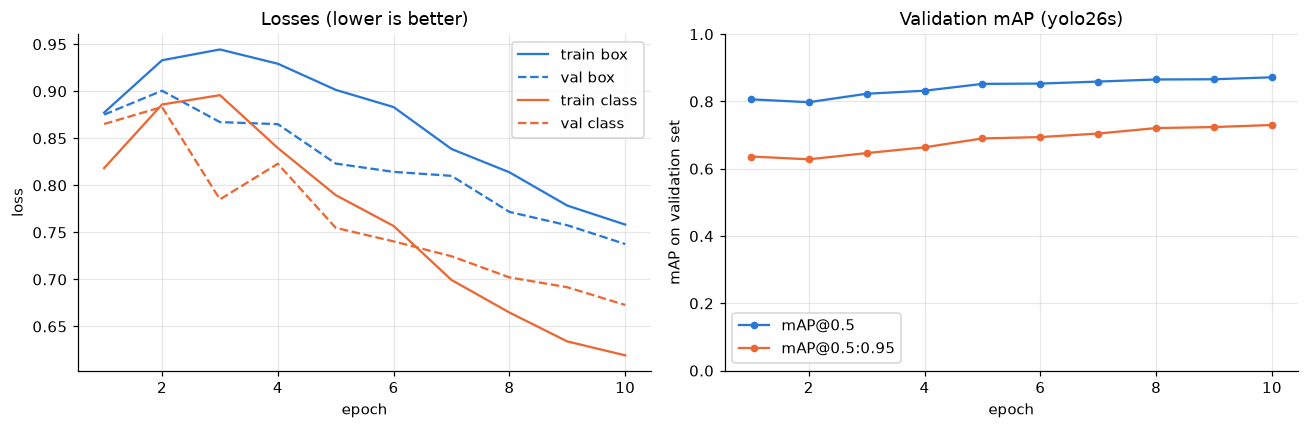

best epoch 10 of 10: val mAP50 0.872, mAP50-95 0.730


In [10]:
res = pd.read_csv(run_dir / "results.csv")
res.columns = [c.strip() for c in res.columns]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for col, lab, c, ls in [("train/box_loss", "train box", "#2a78d6", "-"), ("val/box_loss", "val box", "#2a78d6", "--"),
                        ("train/cls_loss", "train class", "#eb6834", "-"), ("val/cls_loss", "val class", "#eb6834", "--")]:
    if col in res:
        ax[0].plot(res["epoch"], res[col], label=lab, color=c, ls=ls)
ax[0].set(xlabel="epoch", ylabel="loss", title="Losses (lower is better)")
ax[0].legend()
for col, lab, c in [("metrics/mAP50(B)", "mAP@0.5", "#2a78d6"), ("metrics/mAP50-95(B)", "mAP@0.5:0.95", "#eb6834")]:
    ax[1].plot(res["epoch"], res[col], marker="o", ms=4, label=lab, color=c)
ax[1].set(xlabel="epoch", ylabel="mAP on validation set", title=f"Validation mAP ({WINNER})", ylim=(0, 1))
ax[1].legend()
plt.tight_layout()
plt.savefig(OUT_TRAIN / f"{RUN_NAME}_curves.png", bbox_inches="tight")
plt.show()
best_i = int(res["metrics/mAP50-95(B)"].idxmax())
print(f"best epoch {int(res.loc[best_i, 'epoch'])} of {len(res)}: val mAP50 {res.loc[best_i, 'metrics/mAP50(B)']:.3f}, "
      f"mAP50-95 {res.loc[best_i, 'metrics/mAP50-95(B)']:.3f}")

## 9. Validation metrics of the saved weights
Re-loads the file in `weights/` (exactly what the main notebook loads) and evaluates it on the
**validation** split. Test-set numbers are produced only in `traffic_flow_main.ipynb`.

In [11]:
v = val_run(OUT_WEIGHTS)
per_class = pd.DataFrame({"AP50": v.box.ap50, "AP50-95": v.box.ap},
                         index=[CLASS_NAMES[i] for i in v.box.ap_class_index]).round(3)
display(per_class)
print(f"VAL  mAP50={v.box.map50:.3f}  mAP50-95={v.box.map:.3f}  precision={v.box.mp:.3f}  recall={v.box.mr:.3f}"
      + ("   [SMOKE TEST - NOT A RESULT]" if SMOKE_TEST else ""))

,AP50,AP50-95
car,0.921,0.819
two_wheeler,0.918,0.712
auto_rickshaw,0.931,0.801
bus,0.804,0.673
truck,0.785,0.646


VAL  mAP50=0.872  mAP50-95=0.730  precision=0.837  recall=0.800
